# Machine Scheduling

By Efosa Osazuwa

Assign nine candidate jobs to three machines to maximize total profit. Each machine has a capacity measured in job slots, and each job can go to at most one machine. The input includes job durations, but this model uses job counts for capacity.

### Input data

Job     | Profit  | Time |
--------| ------- | ---- |
 1      | 5       | 6    |
 2      | 6       | 7    |
 3      | 2       | 3    |
 4      | 2       | 5    |
 5      | 7       | 10   |
 6      | 3       | 3    |
 7      | 4       | 5    |
 8      | 1       | 3    |
 9      | 12      | 14   |

Machine capacity is measured in jobs.  

 Machine| Capacity | 
--------| ------- | 
 1      | 1       | 
 2      | 2       |
 3      | 3       |

### Algebraic Notation

**Sets**  
machines = $M$   
jobs = $J$  

**Parameters**  
$p_j$ = profit of job $j$  
$c_m$ = work capacity of machine $m$  

**Variables**   
$x_{jm}$ = Indicator of whether machine m is doing job j

**Objective**  
$$
max \sum_{m\in M}\sum_{j\in J} p_jx_{jm}
$$  
The objective is to maximize the profit of the jobs that are taken.  

**Constraints**  
$$
\begin{align}
    \sum_{j \in J} x_{jm} \leq c_m \quad \forall m \in M \tag{1} \\
    \sum_{m \in M} x_{jm} \leq 1 \quad \forall j \in J\tag{2}\\
    x_{jm} \in \{0,1\} \tag{3}
\end{align}
$$  
1: Each machine only has so much work capacity that it can not exceed  
2: No job is chosen more than once  
3: The variable is binary 

## Run the model

Open the [original Google Colab notebook](https://colab.research.google.com/drive/1KwAVGhLQQXo6nM6NkMKrkK0dPJAWRbE_?usp=sharing) or run this copy locally with Python 3.11 and CBC. Install CBC with `brew install cbc` on macOS or `sudo apt install coinor-cbc` on Debian and Ubuntu.

```sh
python3.11 -m venv .venv
source .venv/bin/activate
python -m pip install pyomo==6.9.2 pandas==2.2.3 matplotlib==3.10.1 notebook==7.4.1
jupyter notebook notebooks/machine_scheduling.ipynb
```

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pyomo.environ as pyo
from pyomo.opt import SolverFactory

In [2]:
job_data = [
        {"job": 1,
         "profit": 5,
         "time": 6},
        
        {"job": 2,
         "profit": 6,
         "time": 7},
        
        {"job": 3,
         "profit": 2,
         "time": 3},
        
        {"job": 4,
         "profit": 2,
         "time": 5},
        
        {"job": 5,
         "profit": 7,
         "time": 10},
        
        {"job": 6,
         "profit": 3,
         "time": 3},
        
        {"job": 7,
         "profit": 4,
         "time": 5},
        
        {"job": 8,
         "profit": 1,
         "time": 3},
        
        {"job": 9,
         "profit": 12,
         "time": 14},
]

machine_data = [
                {"capacity": 1},
                {"capacity": 2},
                {"capacity": 3}
]

In [3]:
job_df = pd.DataFrame(job_data)
job_df.index = [f"job_{x}" for x in range(1, 1+len(job_df))]
job_df = job_df.drop(columns=['job'])
job_df

,profit,time
job_1,5,6
job_2,6,7
job_3,2,3
job_4,2,5
job_5,7,10
job_6,3,3
job_7,4,5
job_8,1,3
job_9,12,14


In [4]:
machine_df = pd.DataFrame(machine_data, index=['machine1', 'machine2','machine3'])
machine_df

,capacity
machine1,1
machine2,2
machine3,3


### Binary assignment model

In [5]:
#### MODEL ####

model = pyo.ConcreteModel()

# Sets #
model.machines = pyo.Set(initialize=machine_df.index)
model.jobs = pyo.Set(initialize=job_df.index)

# Params #
model.profit = pyo.Param(model.jobs, initialize=job_df.profit)
model.capacity = pyo.Param(model.machines, initialize=machine_df.capacity)

# Variables #
model.x = pyo.Var(model.jobs, model.machines, within=pyo.Binary)

# Constraints #
model.capacity_constraints = pyo.ConstraintList()
for m in model.machines:
  model.capacity_constraints.add(sum(model.x[j,m] for j in model.jobs) <= model.capacity[m])

model.no_double_dip = pyo.ConstraintList()
for j in model.jobs:
  model.no_double_dip.add(sum(model.x[j,m] for m in model.machines) <= 1)

# Objective #
model.obj = pyo.Objective(expr=sum(model.profit[j]*model.x[j,m] for j in model.jobs for m in model.machines), sense=pyo.maximize)

# Solve #
opt = SolverFactory('cbc')
pyo.assert_optimal_termination(opt.solve(model))

## Results

The optimal profit is **37 units** across six jobs. Because any machine can run any job, several assignments can achieve the same optimum. The blocks show one assignment by machine and represent job slots.

In [6]:
assignments = [
    (machine, job, pyo.value(model.profit[job]))
    for machine in model.machines
    for job in model.jobs
    if round(pyo.value(model.x[job, machine])) == 1
]

print(f"Optimal profit: {pyo.value(model.obj):.0f} units")
pd.DataFrame(assignments, columns=["Machine", "Job", "Profit"])

Optimal profit: 37 units


,Machine,Job,Profit
0,machine1,job_6,3
1,machine2,job_5,7
2,machine2,job_9,12
3,machine3,job_1,5
4,machine3,job_2,6
5,machine3,job_7,4


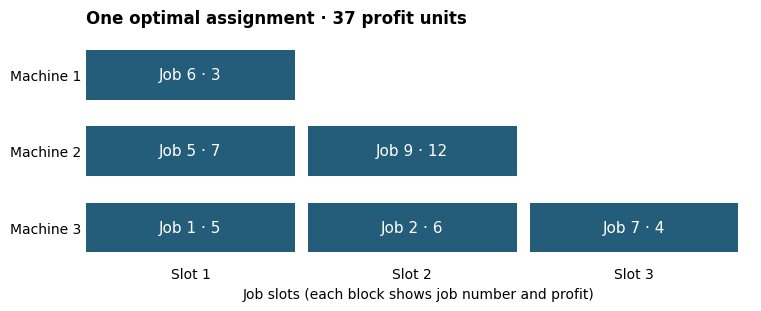

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.0), layout="constrained")
for row, machine in enumerate(model.machines):
    jobs = [(job, profit) for assigned, job, profit in assignments if assigned == machine]
    for slot, (job, profit) in enumerate(jobs):
        ax.barh(row, 0.94, left=slot, height=0.65, align="center", color="#245D7A")
        ax.text(slot + 0.47, row, f"Job {job.split('_')[-1]} · {profit:g}", color="white",
                ha="center", va="center", fontsize=11)

max_capacity = max(machine_df["capacity"])
ax.set_yticks(range(len(machine_df)), [f"Machine {n}" for n in range(1, len(machine_df) + 1)])
ax.set_xticks([slot + 0.47 for slot in range(max_capacity)],
              [f"Slot {slot + 1}" for slot in range(max_capacity)])
ax.set_xlim(0, max_capacity)
ax.invert_yaxis()
ax.set_title(f"One optimal assignment · {pyo.value(model.obj):.0f} profit units",
             loc="left", fontweight="bold", pad=12)
ax.set_xlabel("Job slots (each block shows job number and profit)")
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

### Reflection

The original notebook explored assigning jobs with a simple slot limit. A duration-based version would use the job times and model how long each machine is occupied.